In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Runtime
Comparison between CPU and GPU runtime with varying lattice size.

In [2]:
size = [8, 16, 32, 64, 128, 256, 512, 1024]
temp = [1.5, 3.0]
nsteps = 1000


In [3]:
""" import subprocess
import os

# Clear result files
with open('results.txt', 'w') as f:
    f.write('size\ttemp\tnsweeps\tinit_time_us\tsim_time_ms\n')

with open('results_gpu.txt', 'w') as f:
    f.write('size\ttemp\tnsweeps\tinit_time_us\tsim_time_ms\n')

# Run benchmarks 5 times for each combination
nruns = 5

print("Running CPU benchmarks...")
for s in size:
    for t in temp:
        for run in range(nruns):
            cmd = f"./bench_cpu.x {s} {t} {nsteps}"
            result = subprocess.run(cmd.split(), capture_output=True, text=True, cwd='/home/steve/projects/ising')
            print(f"CPU: size={s}, temp={t}, run={run+1}/{nruns}")
            if result.stderr:
                print(f"  Error: {result.stderr}")

print("\nRunning GPU benchmarks...")
for s in size:
    for t in temp:
        for run in range(nruns):
            cmd = f"./bench_gpu.x {s} {t} {nsteps}"
            result = subprocess.run(cmd.split(), capture_output=True, text=True, cwd='/home/steve/projects/ising')
            print(f"GPU: size={s}, temp={t}, run={run+1}/{nruns}")
            if result.stderr:
                print(f"  Error: {result.stderr}")

print("\nBenchmarks completed!")
 """

' import subprocess\nimport os\n\n# Clear result files\nwith open(\'results.txt\', \'w\') as f:\n    f.write(\'size\ttemp\tnsweeps\tinit_time_us\tsim_time_ms\n\')\n\nwith open(\'results_gpu.txt\', \'w\') as f:\n    f.write(\'size\ttemp\tnsweeps\tinit_time_us\tsim_time_ms\n\')\n\n# Run benchmarks 5 times for each combination\nnruns = 5\n\nprint("Running CPU benchmarks...")\nfor s in size:\n    for t in temp:\n        for run in range(nruns):\n            cmd = f"./bench_cpu.x {s} {t} {nsteps}"\n            result = subprocess.run(cmd.split(), capture_output=True, text=True, cwd=\'/home/steve/projects/ising\')\n            print(f"CPU: size={s}, temp={t}, run={run+1}/{nruns}")\n            if result.stderr:\n                print(f"  Error: {result.stderr}")\n\nprint("\nRunning GPU benchmarks...")\nfor s in size:\n    for t in temp:\n        for run in range(nruns):\n            cmd = f"./bench_gpu.x {s} {t} {nsteps}"\n            result = subprocess.run(cmd.split(), capture_output=True,

In [4]:
import pandas as pd

# Read and display CPU results
print("CPU Results:")
cpu_results = pd.read_csv('results.txt', sep='\t')
print(cpu_results)
print()

# Read and display GPU results
print("GPU Results:")
gpu_results = pd.read_csv('results_gpu.txt', sep='\t')
print(gpu_results)


CPU Results:
    size  temp  nsweeps  init_time_us  sim_time_ms
0      8   1.5     1000            29           10
1      8   1.5     1000            30            8
2      8   1.5     1000            23            8
3      8   1.5     1000            22            8
4      8   1.5     1000            22            7
..   ...   ...      ...           ...          ...
75  1024   3.0     1000        120881       149224
76  1024   3.0     1000        118921       154206
77  1024   3.0     1000        131607       152163
78  1024   3.0     1000        127187       150092
79  1024   3.0     1000        127528       148788

[80 rows x 5 columns]

GPU Results:
    size  temp  nsweeps  init_time_us  sim_time_ms
0      8   1.5     1000       1175823           44
1      8   1.5     1000        136463           26
2      8   1.5     1000        162251           40
3      8   1.5     1000        137932           20
4      8   1.5     1000        144601           25
..   ...   ...      ...         

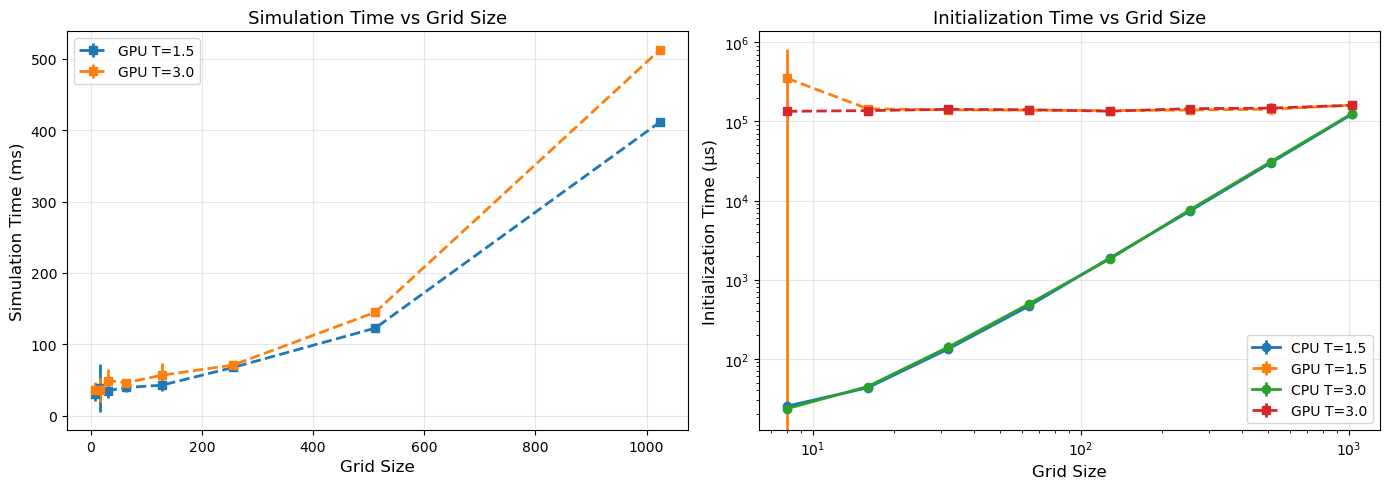

In [15]:
# Simulation time comparison (main simulation, not initialization)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Simulation time for each temperature
for temp_val in temp:
    cpu_data = cpu_results[cpu_results['temp'] == temp_val].groupby('size')['sim_time_ms'].mean()
    gpu_data = gpu_results[gpu_results['temp'] == temp_val].groupby('size')['sim_time_ms'].mean()
    cpu_std = cpu_results[cpu_results['temp'] == temp_val].groupby('size')['sim_time_ms'].std()
    gpu_std = gpu_results[gpu_results['temp'] == temp_val].groupby('size')['sim_time_ms'].std()

    #axes[0].errorbar(cpu_data.index, cpu_data.values, yerr=cpu_std,
    #             label=f'CPU T={temp_val}', linewidth=2, fmt='o-')
    axes[0].errorbar(gpu_data.index, gpu_data.values, yerr=gpu_std,
                 label=f'GPU T={temp_val}', linewidth=2, fmt='s--')

axes[0].set_xlabel('Grid Size', fontsize=12)
axes[0].set_ylabel('Simulation Time (ms)', fontsize=12)
axes[0].set_title('Simulation Time vs Grid Size', fontsize=13)
#axes[0].set_xscale('log')
#axes[0].set_yscale('log')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Initialization time comparison
for temp_val in temp:
    cpu_data = cpu_results[cpu_results['temp'] == temp_val].groupby('size')['init_time_us'].mean()
    gpu_data = gpu_results[gpu_results['temp'] == temp_val].groupby('size')['init_time_us'].mean()
    cpu_std = cpu_results[cpu_results['temp'] == temp_val].groupby('size')['init_time_us'].std()
    gpu_std = gpu_results[gpu_results['temp'] == temp_val].groupby('size')['init_time_us'].std()

    axes[1].errorbar(cpu_data.index, cpu_data.values, yerr=cpu_std,
                 label=f'CPU T={temp_val}', linewidth=2, fmt='o-')
    axes[1].errorbar(gpu_data.index, gpu_data.values, yerr=gpu_std,
                 label=f'GPU T={temp_val}', linewidth=2, fmt='s--')

axes[1].set_xlabel('Grid Size', fontsize=12)
axes[1].set_ylabel('Initialization Time (μs)', fontsize=12)
axes[1].set_title('Initialization Time vs Grid Size', fontsize=13)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


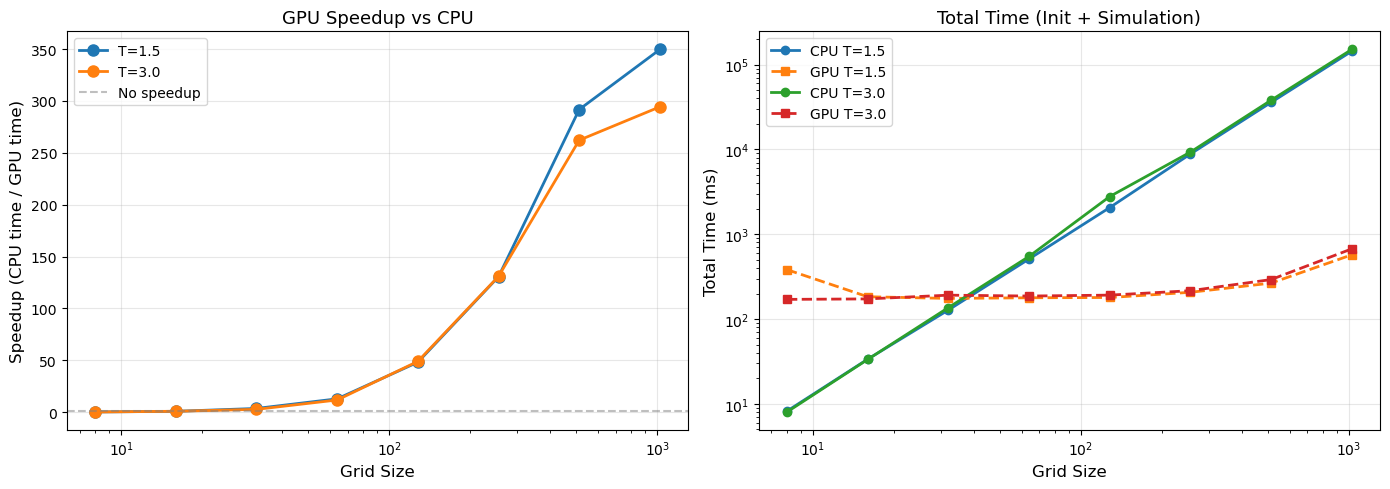

In [6]:
# GPU Speedup (CPU time / GPU time)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for temp_val in temp:
    cpu_data = cpu_results[cpu_results['temp'] == temp_val].groupby('size')['sim_time_ms'].mean()
    gpu_data = gpu_results[gpu_results['temp'] == temp_val].groupby('size')['sim_time_ms'].mean()
    
    speedup = cpu_data / gpu_data
    
    axes[0].plot(speedup.index, speedup.values, 'o-', label=f'T={temp_val}', linewidth=2, markersize=8)

axes[0].set_xlabel('Grid Size', fontsize=12)
axes[0].set_ylabel('Speedup (CPU time / GPU time)', fontsize=12)
axes[0].set_title('GPU Speedup vs CPU', fontsize=13)
axes[0].set_xscale('log')
axes[0].axhline(y=1, color='gray', linestyle='--', alpha=0.5, label='No speedup')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Total time (init + sim) comparison
for temp_val in temp:
    cpu_data = cpu_results[cpu_results['temp'] == temp_val].groupby('size').agg({'init_time_us': 'mean', 'sim_time_ms': 'mean'})
    gpu_data = gpu_results[gpu_results['temp'] == temp_val].groupby('size').agg({'init_time_us': 'mean', 'sim_time_ms': 'mean'})
    
    # Convert init time to ms for comparison
    cpu_total = cpu_data['init_time_us'] / 1000 + cpu_data['sim_time_ms']
    gpu_total = gpu_data['init_time_us'] / 1000 + gpu_data['sim_time_ms']
    
    axes[1].plot(cpu_total.index, cpu_total.values, 'o-', label=f'CPU T={temp_val}', linewidth=2)
    axes[1].plot(gpu_total.index, gpu_total.values, 's--', label=f'GPU T={temp_val}', linewidth=2)

axes[1].set_xlabel('Grid Size', fontsize=12)
axes[1].set_ylabel('Total Time (ms)', fontsize=12)
axes[1].set_title('Total Time (Init + Simulation)', fontsize=13)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
